# 10 · RQ4: What does an unusual claim represent?
**Venkat Repaka and Ritik Gaire · NFIP flood claims**

**Question:** what does an "unusual claim" mean, and does the answer change when we compare buildings with similar buildings?

We have no verified list of errors or fraud, so we cannot measure accuracy. We compare review lists made by different definitions of "unusual" and check what they select.

**Learning bridge:** lecture 09 introduced density as an outlier score, and notebook 04 showed that an unassigned case is not necessarily an error. We begin with one-dimensional density, then a multivariate detector, ratios, peers and external data. Isolation Forest is an extension beyond the class density example.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df=load_joined()

from sklearn.ensemble import IsolationForest

### Step 1 · Define eligible records and review flags
Financial ratios require recorded amounts and positive denominators. Review flags are not verified error labels.

In [2]:
rawcols=['amountPaidOnBuildingClaim','buildingDamageAmount','buildingPropertyValue','totalBuildingInsuranceCoverage','policyCount','numberOfUnits']
d=df[df[rawcols].notna().all(axis=1)&df.buildingPropertyValue.gt(0)&df.totalBuildingInsuranceCoverage.gt(0)&df.buildingDamageAmount.ge(0)].copy()
train=d.loss_year<=2023;test=d.loss_year>=2024
print(f'Eligible fitting claims: {train.sum():,}; later-year claims: {test.sum():,}')
# The date discrepancy is not a detector input.
d['payment_above_coverage']=d.amountPaidOnBuildingClaim>d.totalBuildingInsuranceCoverage+1
d['damage_above_value']=d.buildingDamageAmount>d.buildingPropertyValue
d['date_discrepancy']=(d.openDate<d.dateOfLoss)|(d.mostRecentPaymentDate<d.openDate)
d['any_review_flag']=d[['payment_above_coverage','damage_above_value','date_discrepancy']].any(axis=1)

Eligible fitting claims: 121,111; later-year claims: 92,418


### Step 2 · Begin with density from lecture 09
A low density means few fitting records have a similar payment. We fit one-dimensional KDE to log payment and compare three bandwidths. The bandwidth changes how smooth the density is. Large genuine condo payments can be rare under every bandwidth.

For speed, density is evaluated on a 700-point grid and interpolated for ranking. This is an approximate one-variable score, not a fraud probability.

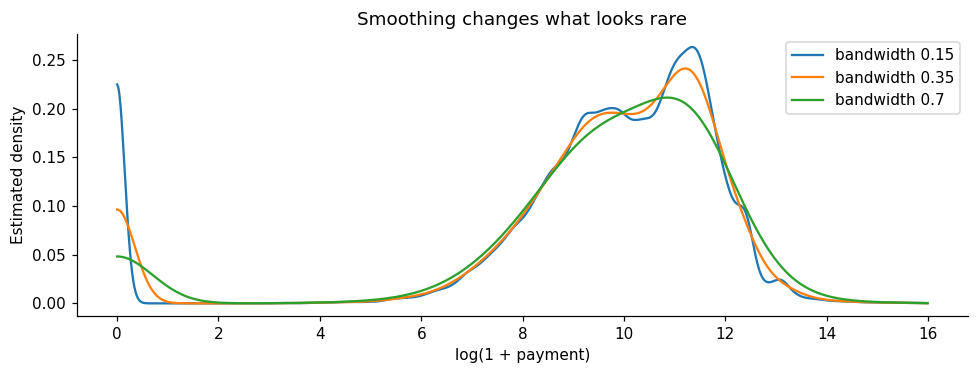

In [3]:
from sklearn.neighbors import KernelDensity
kde_ids=d.loc[train].sample(min(15000,train.sum()),random_state=SEED).index
log_fit=np.log1p(d.loc[kde_ids,'amountPaidOnBuildingClaim']).to_numpy().reshape(-1,1)
log_test=np.log1p(d.loc[test,'amountPaidOnBuildingClaim']).to_numpy()
grid=np.linspace(min(float(log_fit.min()),float(log_test.min())),max(float(log_fit.max()),float(log_test.max())),700)
fig,ax=plt.subplots(figsize=(9,3.5))
for bandwidth in [.15,.35,.7]:
    density=KernelDensity(bandwidth=bandwidth).fit(log_fit)
    log_density=density.score_samples(grid.reshape(-1,1))
    ax.plot(grid,np.exp(log_density),label=f'bandwidth {bandwidth}')
    if bandwidth==.35:kde_scores=pd.Series(-np.interp(log_test,grid,log_density),index=d.index[test])
ax.set(xlabel='log(1 + payment)',ylabel='Estimated density',title='Smoothing changes what looks rare');ax.legend();plt.tight_layout();plt.show()

**Decision.** Keep KDE as a transparent rarity baseline. We do not call its tail cases errors. Next we ask whether considering building size and several financial fields changes the same review list.

## 1. Two ways to define unusual
**General detector:** log payment, damage, value, coverage, policy count and units. This can flag large buildings simply because they are rare.

**Peer detector:** payment/coverage, damage/value, coverage/value and reporting delay. A separate model is fitted within each occupancy type, so single-family homes are compared with single-family homes. Tiny fitting groups use a pooled fallback and are labeled.

Weather is added later, in section 5, as a separate test. It gives broad event context, but it can also make a new storm look unusual or make missing values look unusual. The detector is retrospective: payment and damage are required. The rain and track measurements also have the availability limits explained in notebook 01.

### Step 3 · Define raw-scale and relative representations
Log amounts reduce scale differences. Ratios ask a different question: unusual relative to the building and coverage.

In [4]:
Xglobal=np.log1p(d[rawcols].clip(lower=0))
d['payment_to_coverage']=d.amountPaidOnBuildingClaim/d.totalBuildingInsuranceCoverage
d['damage_to_value']=d.buildingDamageAmount/d.buildingPropertyValue
d['coverage_to_value']=d.totalBuildingInsuranceCoverage/d.buildingPropertyValue
relative=['payment_to_coverage','damage_to_value','coverage_to_value','report_lag_days','rain_5d_mm','trk_dist_km','trk_wind_kt']
# Ratios are not clipped to a presumed valid range: discrepancies should remain visible.
Xrelative=d[relative].copy()
for c in ['payment_to_coverage','damage_to_value','coverage_to_value','rain_5d_mm','trk_dist_km']:
    Xrelative[c]=np.log1p(Xrelative[c].clip(lower=0))

### Step 4 · Fit the multivariate extension on earlier claims
Isolation Forest isolates unusual combinations. Peer models compare within occupancy groups and convert scores to fitting-period percentiles.

In [5]:
from sklearn.impute import SimpleImputer
# The main peer detector uses financial ratios and reporting delay only.
# Weather is tested separately in section 5, because missing weather can dominate the list.
PEER_COLUMNS=relative[:4]
Xpeer=Xrelative[PEER_COLUMNS]
def anomaly_scores(seed=SEED):
    ix=d.index[train]
    if len(ix)>60000:ix=d.loc[ix].sample(60000,random_state=seed).index
    general=IsolationForest(n_estimators=150,max_samples=1024,random_state=seed,n_jobs=-1).fit(Xglobal.loc[ix])
    global_score=pd.Series(-general.score_samples(Xglobal[test]),index=d.index[test])
    pool_pre=SimpleImputer(strategy='median',add_indicator=True).fit(Xpeer.loc[ix])
    pool=IsolationForest(n_estimators=150,max_samples=1024,random_state=seed,n_jobs=-1).fit(pool_pre.transform(Xpeer.loc[ix]))
    peer_score=pd.Series(index=d.index[test],dtype=float)
    fallback=pd.Series(False,index=d.index[test])
    for occ in d.loc[test,'occupancy'].unique():
        a=d.index[train & d.occupancy.eq(occ)];b=d.index[test & d.occupancy.eq(occ)]
        if len(a)<500:
            score=-pool.score_samples(pool_pre.transform(Xpeer.loc[b]))
            ref=-pool.score_samples(pool_pre.transform(Xpeer.loc[ix]));fallback.loc[b]=True
        else:
            if len(a)>40000:a=d.loc[a].sample(40000,random_state=seed).index
            pre=SimpleImputer(strategy='median',add_indicator=True).fit(Xpeer.loc[a])
            mm=IsolationForest(n_estimators=150,max_samples=min(1024,len(a)),random_state=seed,n_jobs=-1).fit(pre.transform(Xpeer.loc[a]))
            score=-mm.score_samples(pre.transform(Xpeer.loc[b]));ref=-mm.score_samples(pre.transform(Xpeer.loc[a]))
        # Training score percentiles make different occupancy models comparable.
        peer_score.loc[b]=np.searchsorted(np.sort(ref),score,side='right')/len(ref)
    return global_score,peer_score,fallback

### Step 5 · Score later claims without refitting on them
A pooled fallback is declared for tiny occupancy fitting groups.

In [6]:
general,peer,fallback=anomaly_scores()
t=d[test].copy();t['weather_missing']=t[['rain_5d_mm','trk_dist_km']].isna().any(axis=1);t['general_score']=general;t['peer_percentile']=peer;t['pooled_fallback']=fallback
print('Later claims using pooled fallback:',int(fallback.sum()))
t['kde_score']=kde_scores

Later claims using pooled fallback: 21


## 2. Compare the same number of reviewed claims
We compare largest payments, the general detector and peer scores at review budgets of 0.5%, 1% and 2%. This is a ranking exercise. Choosing the top 1% does not mean that 1% of claims are truly erroneous.

The review flags are payment above coverage, damage above value and date discrepancies. They are checks for further review, not verified labels. Two flags use quantities also present in detector ratios, so flag enrichment is partly expected and is not independent proof of accuracy. The date flag provides a separate check.

In [7]:
rows=[];rankings={}
for fraction in [.005,.01,.02]:
    k=max(1,round(len(t)*fraction))
    for method,score in [('largest payment','amountPaidOnBuildingClaim'),('univariate KDE','kde_score'),('general forest','general_score'),('peer forest','peer_percentile')]:
        g=t.sort_values([score,'id'],ascending=[False,True]).head(k)
        rankings[(fraction,method)]=g.index
        rows.append({'budget':fraction,'method':method,'reviewed':len(g),'condo share':g.occupancy.eq('15').mean(),
                     'median policies':g.policyCount.median(),'median payment':g.amountPaidOnBuildingClaim.median(),
                     'payment above coverage':g.payment_above_coverage.mean(),'damage above value':g.damage_above_value.mean(),
                     'date discrepancy':g.date_discrepancy.mean(),'any review flag':g.any_review_flag.mean(),'missing weather':g.weather_missing.mean()})
summary=pd.DataFrame(rows).set_index(['budget','method']);display(summary.round(3));save_table(summary,'10_anomaly_comparison')
display(t[['payment_above_coverage','damage_above_value','date_discrepancy','any_review_flag']].mean().to_frame('all eligible later claims'))

reviewed  condo share  median policies  \
budget method                                                    
0.005  largest payment       462        1.000           22.000   
       univariate KDE        462        0.565           11.000   
       general forest        462        0.926           79.500   
       peer forest           462        0.303            1.000   
0.010  largest payment       924        0.779           12.000   
       univariate KDE        924        0.492            1.000   
       general forest        924        0.843           48.000   
       peer forest           924        0.353            1.000   
0.020  largest payment      1848        0.614            6.000   
       univariate KDE       1848        0.407            1.000   
       general forest       1848        0.838           29.000   
       peer forest          1848        0.340            1.000   

                        median payment  payment above coverage  \
budget method                                                    
0.005  largest payment   1,108,827.075                   0.000   
       univariate KDE    1,108,827.075                   0.000   
       general forest      117,669.620                   0.000   
       peer forest          30,292.015                   0.065   
0.010  largest payment     656,438.960                   0.002   
       univariate KDE          466.880                   0.000   
       general forest       73,523.290                   0.000   
       peer forest          52,041.270                   0.063   
0.020  largest payment     500,000.000                   0.001   
       univariate KDE      500,000.000                   0.001   
       general forest       47,822.565                   0.000   
       peer forest          71,016.150                   0.053   

                        damage above value  date discrepancy  any review flag  \
budget method                                                                   
0.005  largest payment               0.076             0.000            0.076   
       univariate KDE                0.074             0.002            0.076   
       general forest                0.015             0.000            0.015   
       peer forest                   0.132             0.000            0.193   
0.010  largest payment               0.043             0.000            0.045   
       univariate KDE                0.038             0.001            0.039   
       general forest                0.011             0.000            0.011   
       peer forest                   0.111             0.000            0.171   
0.020  largest payment               0.025             0.000            0.027   
       univariate KDE                0.022             0.001            0.024   
       general forest                0.017             0.000            0.017   
       peer forest                   0.131             0.000            0.182   

                        missing weather  
budget method                            
0.005  largest payment            0.002  
       univariate KDE             0.004  
       general forest             0.004  
       peer forest                0.253  
0.010  largest payment            0.001  
       univariate KDE             0.002  
       general forest             0.014  
       peer forest                0.245  
0.020  largest payment            0.001  
       univariate KDE             0.003  
       general forest             0.010  
       peer forest                0.240

,all eligible later claims
payment_above_coverage,0.002
damage_above_value,0.008
date_discrepancy,0.000
any_review_flag,0.011


## 3. What are the flagged examples?
We show examples from both detectors and include raw values, storm and occupancy. Look for an understandable reason before describing a claim as an error. The most unusual claim can still be correct.

general detector


,floodEvent,occupancy_name,amountPaidOnBuildingClaim,buildingDamageAmount,buildingPropertyValue,totalBuildingInsuranceCoverage,policyCount,rain_5d_mm,trk_dist_km,payment_above_coverage,damage_above_value,date_discrepancy
271204,None,condo building,0.000,0.000,"100,274,894.000","63,000,000.000",252.000,75.230,"2,781.330",False,False,False
156790,Hurricane Milton,condo building,0.000,0.000,"61,091,365.000","70,500,000.000",282.000,368.040,96.460,False,False,False
161412,None,condo building,0.000,0.000,"47,888,764.000","45,750,000.000",183.000,48.480,"1,013.270",False,False,False
60930,None,condo building,0.000,0.000,"70,239,330.000","39,500,000.000",158.000,41.690,733.820,False,False,False
157042,None,condo building,0.000,0.000,"24,447,438.000","38,500,000.000",154.000,NaN,"5,000.000",False,False,False
48120,June South Florida Flooding,condo building,"1,367,129.740","1,190,737.000","87,791,694.000","130,000,000.000",520.000,481.720,"5,000.000",False,False,False
5983,Hurricane Helene,condo building,0.000,0.000,"26,651,904.000","30,000,000.000",120.000,45.710,181.740,False,False,False
133562,None,condo building,0.000,0.000,"22,481,960.000","30,250,000.000",121.000,0.040,"5,000.000",False,False,False


peer detector


,floodEvent,occupancy_name,amountPaidOnBuildingClaim,buildingDamageAmount,buildingPropertyValue,totalBuildingInsuranceCoverage,policyCount,rain_5d_mm,trk_dist_km,payment_above_coverage,damage_above_value,date_discrepancy
128110,Hurricane Helene,condo building,"452,090.850","419,778.000","2,000.000","1,391,000.000",8.000,45.600,185.890,False,True,False
195763,Hurricane Milton,condo building,"14,207.690","14,407.000",93.000,"87,200.000",1.000,NaN,NaN,False,True,False
241915,2025 July NYC Metro Area Flooding,single family,"134,271.810","128,543.000",249.000,"250,000.000",1.000,146.190,"5,000.000",False,True,False
58327,Hurricane Milton,non-residential,"43,664.740","93,664.000",671.000,"115,000.000",1.000,297.360,64.770,False,True,False
149643,Hurricane Helene,single family,"209,000.000","211,000.000",210.000,"209,000.000",1.000,322.030,125.290,False,True,False
92594,None,single family,"5,376.710","6,626.000",85.000,"220,000.000",1.000,28.690,"5,000.000",False,True,False
196322,None,single family,"2,430.250","4,430.000",79.000,"30,000.000",1.000,31.790,"5,000.000",False,True,False
197566,Hurricane Milton,single family,"38,000.000","41,085.000","1,000.000","38,000.000",1.000,178.340,54.750,False,True,False


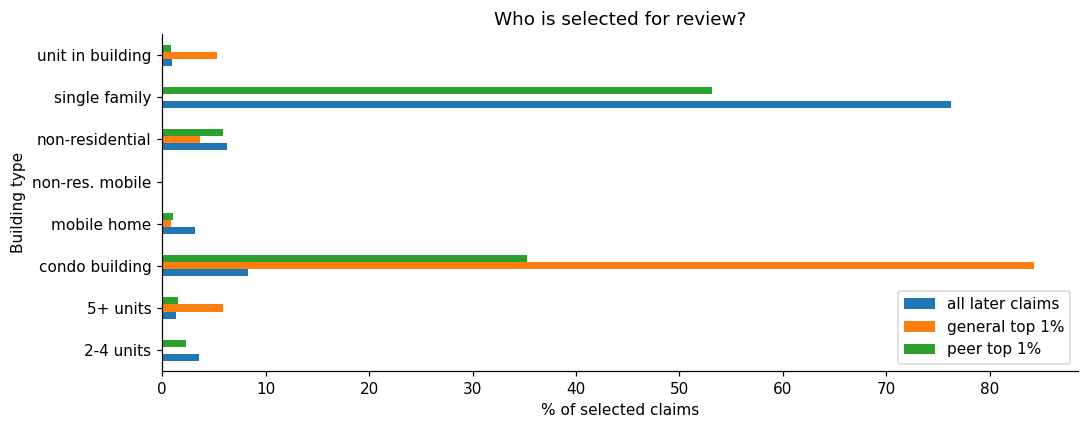

In [8]:
example_cols=['floodEvent','occupancy_name','amountPaidOnBuildingClaim','buildingDamageAmount','buildingPropertyValue',
              'totalBuildingInsuranceCoverage','policyCount','rain_5d_mm','trk_dist_km',
              'payment_above_coverage','damage_above_value','date_discrepancy']
for name,score in [('general detector','general_score'),('peer detector','peer_percentile')]:
    print(name)
    display(t.sort_values([score,'id'],ascending=[False,True]).head(8)[example_cols].round(2))
profile=pd.DataFrame({'all later claims':t.occupancy_name.value_counts(normalize=True),
    'general top 1%':t.loc[rankings[(.01,'general forest')]].occupancy_name.value_counts(normalize=True),
    'peer top 1%':t.loc[rankings[(.01,'peer forest')]].occupancy_name.value_counts(normalize=True)}).fillna(0)
profile.mul(100).plot.barh(figsize=(10,4),title='Who is selected for review?');plt.xlabel('% of selected claims');plt.ylabel('Building type');plt.tight_layout();plt.show()

## 4. Stability and event concentration
We refit both detectors with two more random seeds. Jaccard overlap is the share of selected IDs common to two review lists, divided by the number appearing in either list. One means identical lists.

Peer scores use training percentiles, which can have ties. We break ties by claim ID to make the review budget reproducible. A high share of tied extreme scores limits fine ranking. A storm concentrated at the top can reflect new weather conditions rather than erroneous records.

### Step 6 · A review list should not depend entirely on one seed
We compare selected IDs across repeat fits using Jaccard overlap.

In [9]:
stability=[]
for seed in [7,84]:
    gg,pp,_=anomaly_scores(seed)
    for method,score in [('general forest',gg),('peer forest',pp)]:
        ids=set(score.rename('score').to_frame().assign(id=t.id).sort_values(['score','id'],ascending=[False,True]).head(round(len(t)*.01)).index)
        ref=set(rankings[(.01,method)])
        stability.append({'seed':seed,'method':method,'top 1% Jaccard':len(ids&ref)/len(ids|ref)})
display(pd.DataFrame(stability).set_index(['method','seed']).round(3))

,,top 1% Jaccard
method,seed,
general forest,7,0.812
peer forest,7,0.839
general forest,84,0.876
peer forest,84,0.814


### Step 7 · Check score ties and storm concentration
Ties limit fine ranking. Concentration in one event can reflect new conditions rather than erroneous claims.

In [10]:
print('Peer scores at maximum training percentile:',t.peer_percentile.eq(1).mean())
for method in ['general forest','peer forest']:
    g=t.loc[rankings[(.01,method)]]
    print(method,': event shares')
    display(g.floodEvent.fillna('unnamed').value_counts(normalize=True).head(6).round(3))

Peer scores at maximum training percentile: 1.0820402951805925e-05
general forest : event shares


floodEvent
Hurricane Helene              0.600
Hurricane Milton              0.225
unnamed                       0.078
June South Florida Flooding   0.062
Central U.S. April Flooding   0.014
Hurricane Francine            0.005
Name: proportion, dtype: float64

peer forest : event shares


floodEvent
Hurricane Helene              0.488
Hurricane Milton              0.239
unnamed                       0.176
Hurricane Beryl               0.021
Central U.S. April Flooding   0.017
February Kentucky Flooding    0.011
Name: proportion, dtype: float64

## 5. Separate the effects of ratios, peers and weather
The two main detectors change several things at once. We now compare a pooled ratio detector, a peer ratio detector without weather, and the peer detector with weather. This helps show whether a different review list comes mainly from size normalization, occupancy groups or external event context. We use the same 1% review budget.

We also report missing weather among selected claims. A detector can treat a rare missing-data pattern as unusual. In that case, adding a source may mainly reveal data availability instead of a new flood pattern.

In [11]:
def relative_variant(columns,separate):
    scores=pd.Series(index=d.index[test],dtype=float)
    groups=d.loc[test,'occupancy'].unique() if separate else ['all']
    for group in groups:
        fit_mask=train & d.occupancy.eq(group) if separate else train
        test_mask=test & d.occupancy.eq(group) if separate else test
        a=d.index[fit_mask];b=d.index[test_mask]
        if len(a)<500: a=d.index[train]
        if len(a)>60000:a=d.loc[a].sample(60000,random_state=SEED).index
        pre=SimpleImputer(strategy='median',add_indicator=True).fit(Xrelative.loc[a,columns])
        aa=pre.transform(Xrelative.loc[a,columns]);bb=pre.transform(Xrelative.loc[b,columns])
        detector=IsolationForest(n_estimators=150,max_samples=min(1024,len(a)),random_state=SEED,n_jobs=-1).fit(aa)
        values=-detector.score_samples(bb)
        if separate:
            reference=np.sort(-detector.score_samples(aa))
            values=np.searchsorted(reference,values,side='right')/len(reference)
        scores.loc[b]=values
    return scores

variants={'pooled ratios, no weather':relative_variant(relative[:4],False),
          'peer ratios, no weather':t.peer_percentile,
          'peer ratios + weather':relative_variant(relative,True)}
rows=[]
for name,score in variants.items():
    ids=score.rename('score').to_frame().assign(id=t.id).sort_values(['score','id'],ascending=[False,True]).head(round(len(t)*.01)).index
    g=t.loc[ids]
    rows.append({'design':name,'condo share':g.occupancy.eq('15').mean(),'any review flag':g.any_review_flag.mean(),'missing weather':g.weather_missing.mean(),
                 'date discrepancy':g.date_discrepancy.mean(),'median payment':g.amountPaidOnBuildingClaim.median()})
ablation=pd.DataFrame(rows).set_index('design');display(ablation.round(3));save_table(ablation,'10_design_sensitivity')


,condo share,any review flag,missing weather,date discrepancy,median payment
design,,,,,
"pooled ratios, no weather",0.169,0.219,0.131,0.000,"28,997.555"
"peer ratios, no weather",0.353,0.171,0.245,0.000,"52,041.270"
peer ratios + weather,0.930,0.075,0.957,0.000,"71,231.805"


## 6. Answer and limits
**In simple words.** The first detector marks big buildings as unusual because they are rare. The peer detector compares each building only with similar buildings, and looks at ratios (payment to coverage, damage to value). Its list is less about size and more about odd money patterns.

**What we can and cannot say.** A lower condo share is expected when peers are used. It does not prove the method is more accurate. Only a person checking the original documents can say whether a flagged claim is a real error. We cannot detect fraud from these data. We also do not remove unusual claims before modelling, because they may be real, large losses.

**Check on the date flag.** The "date discrepancy" flag is almost never true in the eligible claims, so it adds little. The other two flags use the same quantities as the ratios, so they are not independent proof.

**Next step.** Draw a small sample of flagged and unflagged claims, chosen before we know the answer, and check them against the documents.

In [12]:
a=summary.loc[(.01,'general forest')];b=summary.loc[(.01,'peer forest')]
display(Markdown(f"**Answer to RQ4.** At the 1% review budget, condos make up **{a['condo share']:.1%}** of the general detector list "
                 f"and **{b['condo share']:.1%}** of the peer detector list. The shares with at least one review flag are "
                 f"**{a['any review flag']:.1%}** and **{b['any review flag']:.1%}**. "
                 "This shows how the definition of unusual changes the review list. It does not establish error-detection accuracy."))

**Answer to RQ4.** At the 1% review budget, condos make up **84.3%** of the general detector list and **35.3%** of the peer detector list. The shares with at least one review flag are **1.1%** and **17.1%**. This shows how the definition of unusual changes the review list. It does not establish error-detection accuracy.

### Decision ledger
We began with large payment and one-variable density, then tested multivariate amounts, relative ratios and occupancy peers. We did not treat rarity as an error label. The weather sensitivity test checks whether an added source detects flood context or merely missing data. Without verified labels, we can improve interpretation and review design but cannot claim improved fraud accuracy.

### Result in plain English

At the 1% review budget, condos are **84.3%** of the list from the general detector and **35.3%** of the list from the peer detector. At least one review flag is true for **1.1%** and **17.1%** of these claims.

Adding weather to the peer detector makes the list **93.0%** condos and **95.7%** of its claims have missing weather. The detector is then finding missing data, not unusual floods, so weather is kept only as a test and not in the main detector.

The review lists show how the meaning of "unusual" changes the result. They are not proof of errors. Only a check of the original documents can show whether a flagged claim is wrong.